# Occupancy: where do mice spend their search time?

Heat maps of where each mouse is while it searches, to answer three questions:

1. **Do mice differ?** Does each mouse have its own map, and do some dwell in particular places?
2. **What changes with experience?** Each mouse's last four sessions minus its first four.
3. **What is different about a good session?** Each mouse's sessions with the most targets found minus those with the fewest.

**The maps.** The arena is cut into 20 x 44 bins, a quarter of a target cell on a side. A map is the share of **search** time (trial start to target found) the body centroid spends in each bin, scaled so that **1 means as much time as if the mouse spread its time evenly** over the arena, 2 means twice that, and so on. Time spent walking to the port, drinking and waiting is left out, except in the one figure that shows it for contrast.

**Reading them.** The arena is drawn on its side: the long axis runs left to right, low-y end on the left. The thin rectangle is the edge of the 3 x 9 grid of target cells, and the two short lines mark the middle row, where the ports are. The position is the body centroid, which sits about one cell behind the nose.

**Zones.** The body centroid never comes within about half a cell of the edge of the camera frame at the sides, or three quarters of a cell at the ends, so the dark border of every map is space the mouse's body cannot occupy. Zones are therefore defined from the area it does reach:

- **wall lane** - within three quarters of a cell (133 px) of the edge of the reachable area. This is where the centroid is when a mouse runs along a wall. Note that most of it lies just *inside* the rectangle, over the outermost target cells, not outside it.
- **at the ports** - the few bins that hold most of the non-search time. A search starts with the mouse still at a port, so these would otherwise count as wall.
- **interior** - everything else the mouse can reach.

**A caution about search occupancy.** A search ends at the target, so occupancy during search is pulled toward wherever targets are. That is why the earlier notebooks do not use it to compare trial types. Here every comparison is between sessions or mice that have the same mix of target locations, so the pull is the same on both sides and cancels.

Odor `x` and vision `v` sessions, each mouse's first ten of each (mouse 9000 has six vision sessions).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats as sps

from src import config as cfg
from src.trials import load_trials
from src.occupancy import load_occupancy, X_EDGES, Y_EDGES     # run `python -m src.occupancy` to rebuild output/occupancy*.npz

pd.set_option('display.width', 200, 'display.precision', 3)

EXPERIMENTS = ['odor', 'vision']
EXP_COLOR = {'odor': '#2a78d6', 'vision': '#7a52c7'}
EXP_LABEL = {'odor': "odor 'x'", 'vision': "vision 'v'"}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'legend.frameon': False, 'figure.dpi': 110,
})

loaded = [load_occupancy(e) for e in EXPERIMENTS]
ses = pd.concat([l[0] for l in loaded], ignore_index=True)            # one row per session, aligned with the maps
search_s = np.concatenate([l[1] for l in loaded])                     # [session, y bin, x bin], seconds
other_s = np.concatenate([l[2] for l in loaded])

def density(maps):
    """Share of time per bin, scaled so 1 = time spread evenly over the arena."""
    return maps / maps.sum(axis=(-2, -1), keepdims=True) * maps.shape[-2] * maps.shape[-1]

D = density(search_s)
MICE = sorted(ses.mouse.unique())

finds = pd.concat([load_trials(e).assign(experiment=e) for e in EXPERIMENTS]).groupby(['experiment', 'mouse', 'session']).size().rename('finds')
ses = ses.join(finds, on=['experiment', 'mouse', 'session'])
ses['n_sessions'] = ses.groupby(['experiment', 'mouse']).session_num.transform('max')

# where each bin is, relative to the area the body centroid actually reaches
xc, yc = (X_EDGES[:-1] + X_EDGES[1:]) / 2, (Y_EDGES[:-1] + Y_EDGES[1:]) / 2
XX, YY = np.meshgrid(xc, yc)
pooled = density((search_s + other_s).sum(axis=0))
reach_x, reach_y = xc[pooled.mean(axis=0) > 0.05], yc[pooled.mean(axis=1) > 0.05]
half_x, half_y = np.diff(X_EDGES)[0] / 2, np.diff(Y_EDGES)[0] / 2
REACH = dict(x0=reach_x.min() - half_x, x1=reach_x.max() + half_x, y0=reach_y.min() - half_y, y1=reach_y.max() + half_y)
to_end = np.minimum(YY - REACH['y0'], REACH['y1'] - YY)
wall_dist = np.minimum(np.minimum(XX - REACH['x0'], REACH['x1'] - XX), to_end)       # px inside the reachable edge; negative = outside
LANE = 0.75 * cfg.CELL_W
lane = (wall_dist > 0) & (wall_dist < LANE)
ports = density(other_s.sum(axis=0)) > 10            # the bins that hold the non-search time
ZONES = {'wall lane': lane & ~ports, '   along the side walls': lane & (to_end >= LANE) & ~ports, '   along the end walls': lane & (to_end < LANE) & ~ports,
         'at the ports': ports, 'interior': (wall_dist >= LANE) & ~ports}
print('reachable area (px):', {k: round(v) for k, v in REACH.items()}, '| bins:', {name.strip(): int(mask.sum()) for name, mask in ZONES.items()})
zone_share = pd.DataFrame({name: search_s[:, mask].sum(axis=1) / search_s.sum(axis=(1, 2)) for name, mask in ZONES.items()})

def show(ax, m, cmap='magma', vmin=0, vmax=3, title=None, lines='#fcfcfb'):
    """Draw one map with the arena on its side: long axis left to right, low-y end on the left."""
    im = ax.imshow(m.T, origin='lower', extent=(0, cfg.FRAME_H, 0, cfg.FRAME_W), cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.add_patch(Rectangle((cfg.CELL_H, cfg.CELL_W), cfg.FRAME_H - 2 * cfg.CELL_H, cfg.FRAME_W - 2 * cfg.CELL_W, fill=False, edgecolor=lines, lw=0.6))
    for y in (cfg.LOW_MAX_Y, cfg.HIGH_MIN_Y):
        ax.plot([y, y], [cfg.CELL_W, cfg.CELL_W + 60], color=lines, lw=0.6)
        ax.plot([y, y], [cfg.FRAME_W - cfg.CELL_W - 60, cfg.FRAME_W - cfg.CELL_W], color=lines, lw=0.6)
    ax.set(xticks=[], yticks=[])
    for side in ax.spines.values():
        side.set_visible(False)
    if title is not None:
        ax.set_title(title, fontsize=8, fontweight='normal', pad=2)
    return im

def colorbar(fig, im, axes, label):
    cb = fig.colorbar(im, ax=axes, shrink=0.7, pad=0.01, aspect=30)
    cb.set_label(label, fontsize=8); cb.ax.tick_params(labelsize=7); cb.outline.set_visible(False)

reachable area (px): {'x0': 89, 'x1': 799, 'y0': 134, 'y1': 1834} | bins: {'wall lane': 272, 'along the side walls': 176, 'along the end walls': 96, 'at the ports': 16, 'interior': 320}


## 1. The average map

Search time on top; all other time (walking to a port, drinking, waiting out the ITI) below, on its own color scale because it is concentrated at the two ports.

experiment,odor,vision
mice,9.000,9.000
sessions,90.000,86.000
search time per session (min),28.354,26.754
other time per session (min),16.464,18.401
share of search time: wall lane,0.492,0.427
share of search time: along the side walls,0.254,0.198
share of search time: along the end walls,0.239,0.229
share of search time: at the ports,0.047,0.031
share of search time: interior,0.459,0.541


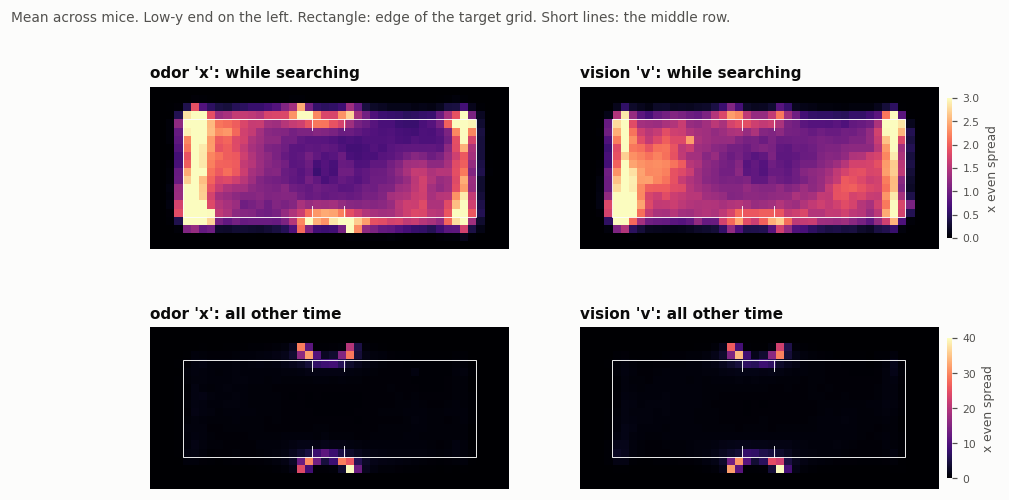

In [2]:
overview = ses.groupby('experiment').agg(mice=('mouse', 'nunique'), sessions=('session', 'size'))
overview['search time per session (min)'] = pd.Series(search_s.sum(axis=(1, 2)) / 60).groupby(ses.experiment).mean()
overview['other time per session (min)'] = pd.Series(other_s.sum(axis=(1, 2)) / 60).groupby(ses.experiment).mean()
display(overview.join(zone_share.groupby(ses.experiment).mean().add_prefix('share of search time: ')).loc[EXPERIMENTS].T)

def mean_over_mice(maps, keep):
    """Mean map across mice of each mouse's mean map over its sessions in `keep`."""
    return np.mean([maps[g.index].mean(axis=0) for _, g in ses[keep].groupby('mouse')], axis=0)

fig, axes = plt.subplots(2, 2, figsize=(11, 5.2))
for col, exp in enumerate(EXPERIMENTS):
    im_s = show(axes[0, col], mean_over_mice(D, ses.experiment == exp))
    im_o = show(axes[1, col], mean_over_mice(density(other_s), ses.experiment == exp), vmax=40)
    axes[0, col].set_title(f'{EXP_LABEL[exp]}: while searching', fontsize=10, fontweight='bold')
    axes[1, col].set_title(f'{EXP_LABEL[exp]}: all other time', fontsize=10, fontweight='bold')
colorbar(fig, im_s, axes[0], 'x even spread')
colorbar(fig, im_o, axes[1], 'x even spread')
fig.suptitle('Mean across mice. Low-y end on the left. Rectangle: edge of the target grid. Short lines: the middle row.', x=0.01, ha='left', fontsize=9, color=MUTED)
plt.show()

While searching, mice are not spread evenly. The brightest track runs around the arena about half a cell in from the edge of the reachable area - a body's width from the wall - and is strongest across the two ends. The bright spots halfway along each side wall are the ports: a search begins with the mouse still there. The center of the arena gets close to an even share.

In numbers: the wall lane holds 49% of search time in the odor sessions and 43% in vision, the interior 46% and 54%, and the ports 5% and 3%.

When not searching, mice are at the ports and almost nowhere else, which is why that time is left out of everything below.

## 2. Every session of every mouse

One row per mouse, one column per session (its 1st to 10th of the experiment). The color scale is the same in every panel. Each title gives the session and the number of targets found in it.

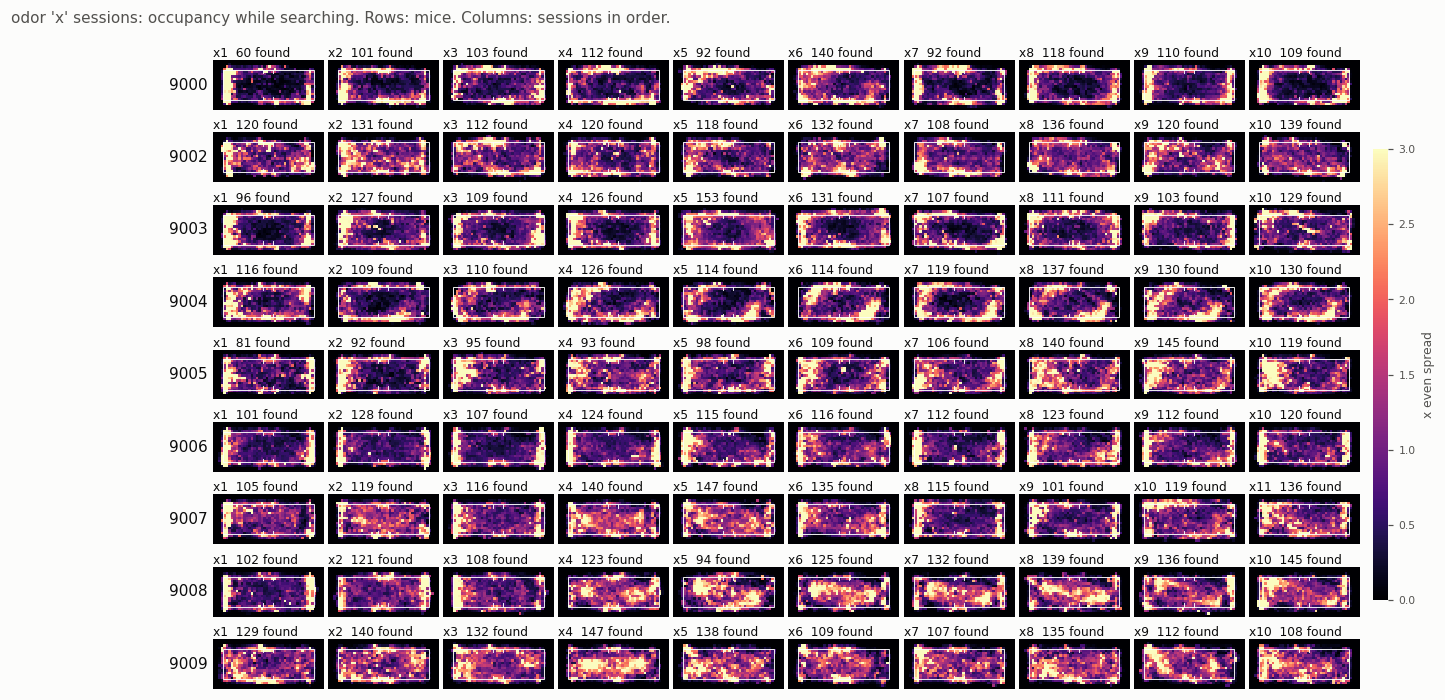

In [3]:
def session_grid(exp):
    fig, axes = plt.subplots(len(MICE), 10, figsize=(16, 7.6), gridspec_kw={'wspace': 0.04, 'hspace': 0.12})
    for row, mouse in zip(axes, MICE):
        for n, ax in enumerate(row, start=1):
            hit = ses[(ses.experiment == exp) & (ses.mouse == mouse) & (ses.session_num == n)]
            if len(hit):
                im = show(ax, D[hit.index[0]], title=f"{hit.session.iloc[0]}  {int(hit.finds.iloc[0])} found")
            else:
                ax.axis('off')
        row[0].set_ylabel(mouse, rotation=0, ha='right', va='center', color=INK, fontsize=10)
    colorbar(fig, im, axes, 'x even spread')
    fig.suptitle(f'{EXP_LABEL[exp]} sessions: occupancy while searching. Rows: mice. Columns: sessions in order.', x=0.01, y=0.93, ha='left', fontsize=10, color=MUTED)
    plt.show()

session_grid('odor')

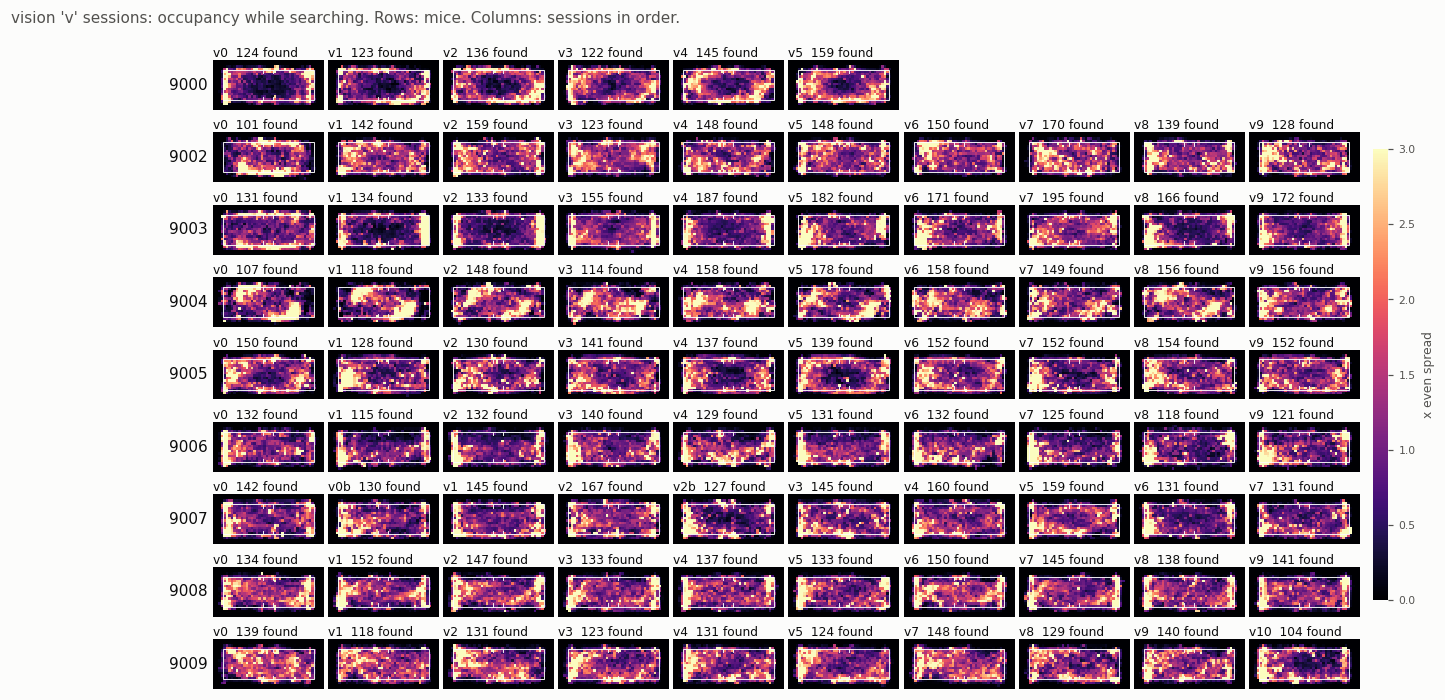

In [4]:
session_grid('vision')

## 3. Do mice differ?

**Each mouse's own map**, averaged over its sessions, and below it the same map **minus the average of all mice** in that experiment: red where this mouse spends more time than mice in general, blue where it spends less.

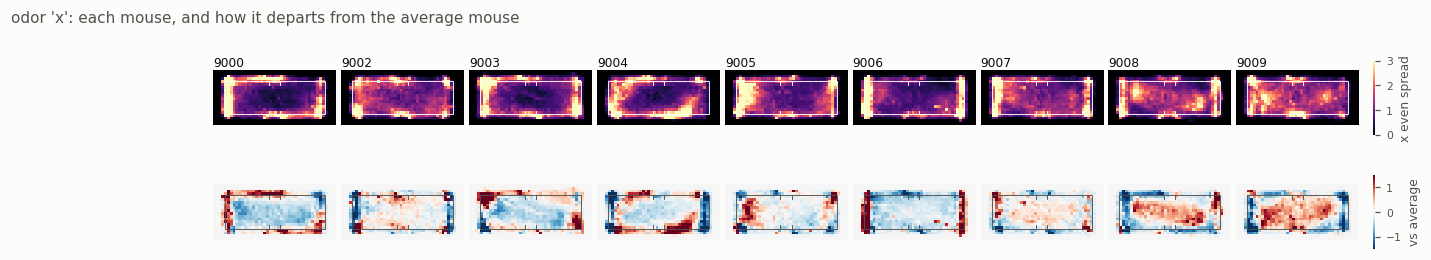

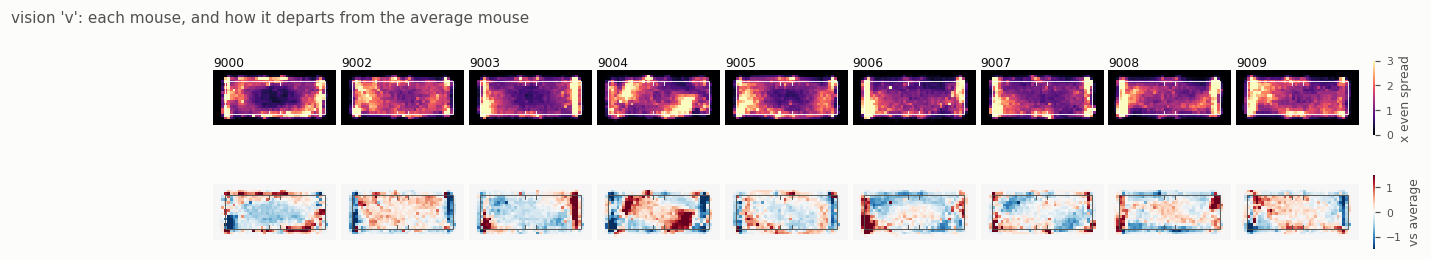

In [5]:
mouse_map = {(exp, m): D[g.index].mean(axis=0) for (exp, m), g in ses.groupby(['experiment', 'mouse'])}
group_map = {exp: np.mean([mouse_map[exp, m] for m in MICE], axis=0) for exp in EXPERIMENTS}

for exp in EXPERIMENTS:
    fig, axes = plt.subplots(2, len(MICE), figsize=(16, 2.6), gridspec_kw={'wspace': 0.04, 'hspace': 0.08})
    for col, m in enumerate(MICE):
        im_a = show(axes[0, col], mouse_map[exp, m], title=m)
        im_b = show(axes[1, col], mouse_map[exp, m] - group_map[exp], cmap='RdBu_r', vmin=-1.5, vmax=1.5, lines=MUTED)
    colorbar(fig, im_a, axes[0], 'x even spread')
    colorbar(fig, im_b, axes[1], 'vs average')
    fig.suptitle(f'{EXP_LABEL[exp]}: each mouse, and how it departs from the average mouse', x=0.01, y=1.0, ha='left', fontsize=10, color=MUTED)
    plt.show()

**Is a mouse's map its own?** If mice have individual habits, two sessions from the same mouse should look more alike than two sessions from different mice. Similarity here is the correlation between two sessions' maps across bins. The matrix shows it for every pair of sessions, sorted by mouse; blocks along the diagonal are mice that resemble themselves.

The second test is stricter: does a mouse's departure from the average mouse in the odor sessions predict its departure in the vision sessions, weeks later?

,"same mouse, different sessions",different mice,difference,p (paired t),mice more like themselves
odor 'x',0.574,0.415,0.159,0.0,9/9
vision 'v',0.593,0.472,0.122,0.0,9/9


departure from the average mouse, odor vs vision: same mouse r = 0.43, different mice r = -0.05, paired p = 0.0003, 9/9 mice more like themselves


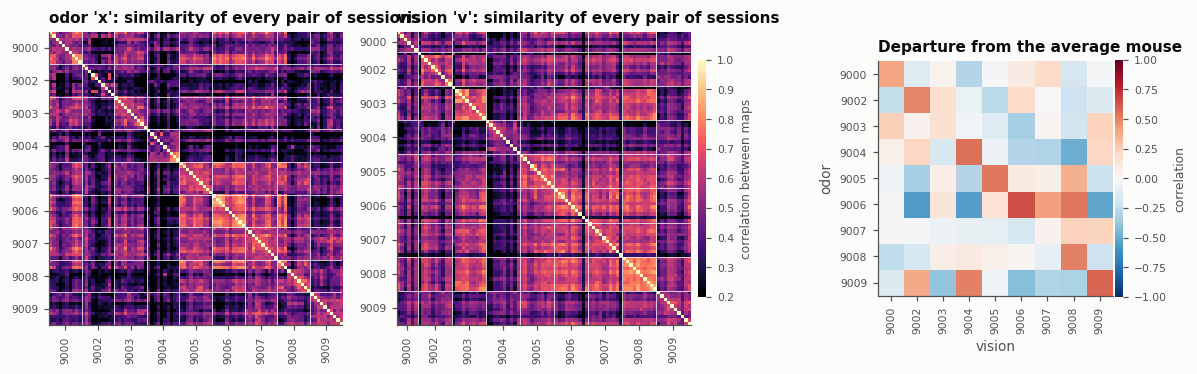

In [6]:
flat = D.reshape(len(D), -1)
similarity = np.corrcoef(flat)
same_exp = ses.experiment.to_numpy()[:, None] == ses.experiment.to_numpy()[None, :]
same_mouse = ses.mouse.to_numpy()[:, None] == ses.mouse.to_numpy()[None, :]
other_session = ~np.eye(len(ses), dtype=bool)

rows = {}
for exp in EXPERIMENTS:
    own, others = {}, {}
    for m, g in ses[ses.experiment == exp].groupby('mouse'):
        i = g.index.to_numpy()
        own[m] = similarity[np.ix_(i, i)][other_session[np.ix_(i, i)]].mean()
        others[m] = similarity[i][:, (same_exp[i[0]] & ~same_mouse[i[0]])].mean()
    own, others = pd.Series(own), pd.Series(others)
    rows[EXP_LABEL[exp]] = {'same mouse, different sessions': own.mean(), 'different mice': others.mean(), 'difference': (own - others).mean(),
                            'p (paired t)': sps.ttest_rel(own, others).pvalue, 'mice more like themselves': f'{int((own > others).sum())}/{len(own)}'}
display(pd.DataFrame(rows).T)

# a mouse's departure from the average mouse, odor against vision
departure = {exp: np.array([(mouse_map[exp, m] - group_map[exp]).ravel() for m in MICE]) for exp in EXPERIMENTS}
across = np.corrcoef(departure['odor'], departure['vision'])[:len(MICE), len(MICE):]       # [odor mouse, vision mouse]
same, different = np.diag(across), (across.sum(axis=1) - np.diag(across)) / (len(MICE) - 1)
print(f"departure from the average mouse, odor vs vision: same mouse r = {same.mean():.2f}, different mice r = {different.mean():.2f}, "
      f"paired p = {sps.ttest_rel(same, different).pvalue:.4f}, {int((same > different).sum())}/{len(MICE)} mice more like themselves")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw={'width_ratios': [1, 1, 0.8]})
for ax, exp in zip(axes, EXPERIMENTS):
    i = ses.index[ses.experiment == exp].to_numpy()
    im = ax.imshow(similarity[np.ix_(i, i)], cmap='magma', vmin=0.2, vmax=1, interpolation='nearest')
    edges = np.flatnonzero(np.r_[True, ses.mouse[i].to_numpy()[1:] != ses.mouse[i].to_numpy()[:-1], True])
    ax.set(xticks=(edges[:-1] + edges[1:]) / 2 - 0.5, xticklabels=MICE, yticks=(edges[:-1] + edges[1:]) / 2 - 0.5, yticklabels=MICE,
           title=f'{EXP_LABEL[exp]}: similarity of every pair of sessions')
    ax.tick_params(axis='x', rotation=90, labelsize=7); ax.tick_params(axis='y', labelsize=7)
    for e in edges[1:-1]:
        ax.axhline(e - 0.5, color='#fcfcfb', lw=0.5); ax.axvline(e - 0.5, color='#fcfcfb', lw=0.5)
colorbar(fig, im, axes[:2], 'correlation between maps')
im = axes[2].imshow(across, cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest')
axes[2].set(xticks=range(len(MICE)), xticklabels=MICE, yticks=range(len(MICE)), yticklabels=MICE, xlabel='vision', ylabel='odor',
            title='Departure from the average mouse')
axes[2].tick_params(axis='x', rotation=90, labelsize=7); axes[2].tick_params(axis='y', labelsize=7)
colorbar(fig, im, axes[2], 'correlation')
plt.show()

**Yes, mice have their own maps, and they keep them.**
- Two sessions from the same mouse are more alike than two sessions from different mice: correlation 0.57 against 0.42 in odor, 0.59 against 0.47 in vision, in all nine mice in both.
- The individual pattern carries over from one experiment to the next. A mouse's departure from the average mouse in odor correlates 0.43 with its own departure in vision, and -0.05 with other mice's (9/9 mice).

**What the differences look like** (section 2 and the maps above):
- Some mice are wall-runners: 9000, 9003 and 9006 trace the edge and leave the center nearly empty, in most sessions.
- Some use the interior: 9008 and 9009 fill the middle of the arena.
- 9004 has the most distinctive map: two hot spots at diagonally opposite corners of the grid, which appear partway through the odor sessions and persist through vision.
- One thing they share: every mouse spends at least half of its search time in the low-y half of the arena (52-60% in odor, 50-60% in vision).

## 4. With experience: last four sessions minus first four

For each mouse, the mean map of its last four sessions minus the mean map of its first four. Red: more time there late than early. Blue: less. Three comparisons:

- within the odor sessions,
- within the vision sessions (mouse 9000 is left out: with six sessions its first four and last four overlap),
- across the whole history: the last four vision sessions minus the first four odor sessions.

The large maps are the mean across mice. The small ones are each mouse.

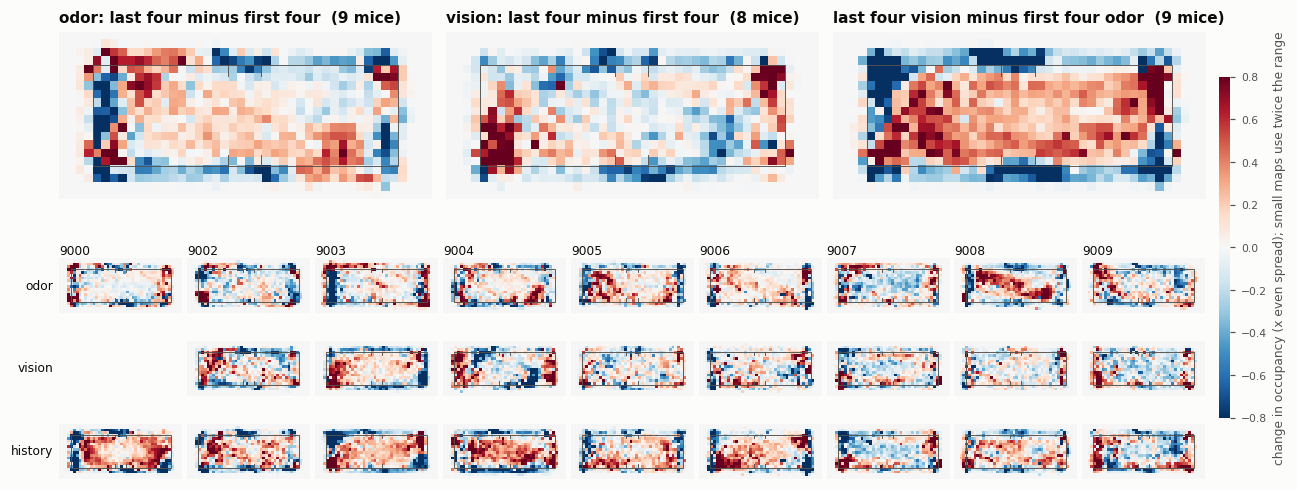

In [7]:
first4 = ses.session_num <= 4
last4 = ses.session_num > ses.n_sessions - 4
enough = ses.n_sessions >= 8                       # first four and last four do not overlap
odor, vision = ses.experiment == 'odor', ses.experiment == 'vision'
CHANGES = {'odor: last four minus first four': (odor & first4, odor & last4 & enough),
           'vision: last four minus first four': (vision & first4 & enough, vision & last4 & enough),
           'last four vision minus first four odor': (odor & first4, vision & last4)}

def per_mouse_maps(keep):
    return {m: D[g.index].mean(axis=0) for m, g in ses[keep].groupby('mouse')}

def difference_maps(before, after):
    """{mouse: after map - before map}, for mice that have both."""
    a, b = per_mouse_maps(before), per_mouse_maps(after)
    return {m: b[m] - a[m] for m in MICE if m in a and m in b}

def difference_figure(contrasts, vlim=0.8):
    fig = plt.figure(figsize=(16, 2.9 + 0.95 * len(contrasts)))
    outer = fig.add_gridspec(2, 1, height_ratios=[2.6, 0.95 * len(contrasts)], hspace=0.08)
    top = outer[0].subgridspec(1, len(contrasts), wspace=0.04)
    bottom = outer[1].subgridspec(len(contrasts), len(MICE), wspace=0.04, hspace=0.05)
    axes = []
    for k, (name, (before, after)) in enumerate(contrasts.items()):
        diffs = difference_maps(before, after)
        ax = fig.add_subplot(top[0, k]); axes.append(ax)
        im = show(ax, np.mean(list(diffs.values()), axis=0), cmap='RdBu_r', vmin=-vlim, vmax=vlim, lines=MUTED)
        ax.set_title(f'{name}  ({len(diffs)} mice)', fontsize=10, fontweight='bold')
        for col, m in enumerate(MICE):
            ax = fig.add_subplot(bottom[k, col]); axes.append(ax)
            if m in diffs:
                show(ax, diffs[m], cmap='RdBu_r', vmin=-vlim * 2, vmax=vlim * 2, lines=MUTED, title=m if k == 0 else None)
            else:
                ax.set(xticks=[], yticks=[])
                for side in ax.spines.values():
                    side.set_visible(False)
            if col == 0:
                ax.set_ylabel(name.split(':')[0] if ':' in name else 'history', rotation=0, ha='right', va='center', fontsize=8, color=INK)
    colorbar(fig, im, axes, 'change in occupancy (x even spread); small maps use twice the range')
    plt.show()

difference_figure(CHANGES)

The same change in numbers: the share of search time in each zone, per mouse, before and after.

In [8]:
def zone_change(before, after):
    a = zone_share[before].groupby(ses.mouse[before]).mean()
    b = zone_share[after].groupby(ses.mouse[after]).mean()
    a, b = a.loc[a.index.intersection(b.index)], b.loc[a.index.intersection(b.index)]
    diff = b - a
    return pd.DataFrame({'before': a.mean(), 'after': b.mean(), 'change': diff.mean(), 'p (paired t)': sps.ttest_rel(b, a).pvalue,
                         'mice down': [f'{int((diff[c] < 0).sum())}/{len(diff)}' for c in diff]})

experience_zones = pd.concat({name: zone_change(*keep) for name, keep in CHANGES.items()})
experience_zones

before  after  change  p (paired t) mice down
odor: last four minus first four       wall lane                 0.515  0.491  -0.024     3.794e-01       4/9
                                          along the side walls   0.251  0.253   0.002     9.052e-01       4/9
                                          along the end walls    0.264  0.238  -0.026     2.874e-01       5/9
                                       at the ports              0.052  0.039  -0.013     1.142e-02       8/9
                                       interior                  0.431  0.467   0.036     2.407e-01       3/9
vision: last four minus first four     wall lane                 0.419  0.420   0.001     9.607e-01       3/8
                                          along the side walls   0.205  0.180  -0.024     8.007e-02       5/8
                                          along the end walls    0.214  0.240   0.026     2.504e-01       2/8
                                       at the ports              0.035  0.023  -0.012     9.693e-03       7/8
                                       interior                  0.545  0.556   0.011     6.317e-01       5/8
last four vision minus first four odor wall lane                 0.515  0.424  -0.091     1.559e-02       7/9
                                          along the side walls   0.251  0.191  -0.060     3.557e-02       7/9
                                          along the end walls    0.264  0.232  -0.031     3.418e-01       6/9
                                       at the ports              0.052  0.025  -0.027     3.392e-04       9/9
                                       interior                  0.431  0.551   0.120     5.846e-03       2/9

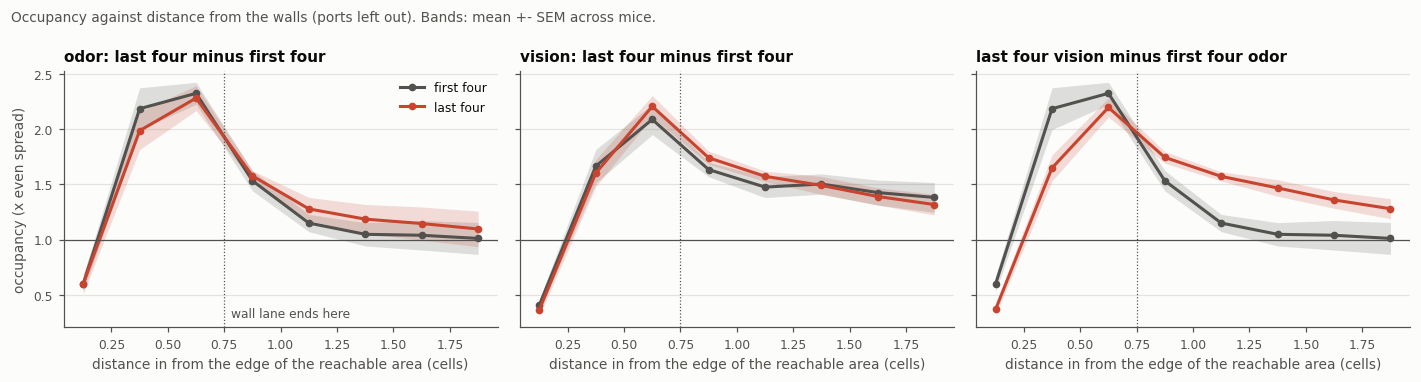

In [9]:
DIST_EDGES = np.arange(0, (REACH['x1'] - REACH['x0']) / 2 + 1, cfg.CELL_W / 4)
band = np.where(ports | (wall_dist <= 0), -1, np.digitize(wall_dist, DIST_EDGES) - 1)      # ports and unreachable bins left out

def wall_profile(keep):
    """Per mouse (rows), occupancy by distance from the nearest wall: mean density of the bins in each distance band."""
    return pd.DataFrame({m: [d[band == k].mean() for k in range(len(DIST_EDGES) - 1)] for m, d in per_mouse_maps(keep).items()}).T

fig, axes = plt.subplots(1, len(CHANGES), figsize=(13, 3.5), sharey=True)
mid_dist = (DIST_EDGES[:-1] + DIST_EDGES[1:]) / 2 / cfg.CELL_W
for ax, (name, (before, after)) in zip(axes, CHANGES.items()):
    for keep, color, label in ((before, MUTED, 'first four'), (after, '#c8442f', 'last four')):
        p = wall_profile(keep)
        ax.fill_between(mid_dist, p.mean() - p.sem(), p.mean() + p.sem(), color=color, alpha=0.18, lw=0)
        ax.plot(mid_dist, p.mean(), color=color, lw=2, marker='o', ms=4, label=label)
    ax.axvline(LANE / cfg.CELL_W, color=MUTED, lw=0.8, ls=':'); ax.axhline(1, color=MUTED, lw=0.8)
    ax.set(title=name, xlabel='distance in from the edge of the reachable area (cells)')
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel('occupancy (x even spread)'); axes[0].legend()
axes[0].text(LANE / cfg.CELL_W + 0.03, 0.04, 'wall lane ends here', fontsize=8, color=MUTED, transform=axes[0].get_xaxis_transform())
fig.suptitle('Occupancy against distance from the walls (ports left out). Bands: mean +- SEM across mice.', x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

**Within an experiment the change is small.** From the first four to the last four sessions, the wall lane's share of search time does not change reliably in odor (51% to 49%) or in vision (42% in both). The one consistent change is at the ports: mice spend less of the search there (-1.3 points in odor, 8/9 mice; -1.2 in vision, 7/8 mice), which is to say they get going sooner once a trial starts.

**Across the whole history the shift is clear.** From the first four odor sessions to the last four vision sessions:
- the wall lane falls from 51% of search time to 42% (7/9 mice), mostly along the side walls (25% to 19%);
- time at the ports halves (5.2% to 2.5%, 9/9 mice);
- the interior rises from 43% to 55% (7/9 mice).

The map shows where: blue all the way round the edge, deepest along the low-y end wall and both side walls, and red across the whole interior. The profile says the same thing: occupancy falls in the outermost half cell and rises everywhere more than one cell in.

Individual mice vary. Most show the edge-to-interior shift over the whole history, but 9007 goes the other way.

## 5. Good sessions minus poor sessions

For each mouse and experiment, the three sessions with the most targets found minus the three with the fewest. This is not the same comparison as section 4: a mouse's best sessions are not all its latest ones.

finds  mean_session_number
experiment kind                                   
odor       best three   134.6                  7.0
           worst three  102.1                  4.5
vision     best three   155.6                  5.9
           worst three  123.7                  4.0

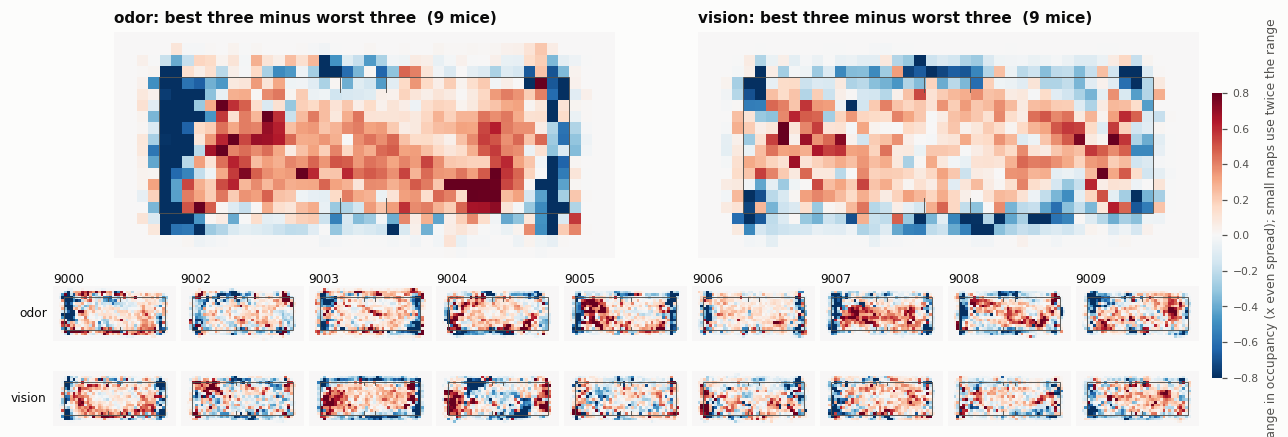

before  after  change  p (paired t) mice down
odor: best three minus worst three   wall lane                 0.544  0.458  -0.086         0.002       9/9
                                        along the side walls   0.263  0.259  -0.003         0.844       5/9
                                        along the end walls    0.281  0.199  -0.082         0.001       9/9
                                     at the ports              0.052  0.043  -0.009         0.194       7/9
                                     interior                  0.402  0.496   0.093         0.003       0/9
vision: best three minus worst three wall lane                 0.453  0.399  -0.054         0.051       7/9
                                        along the side walls   0.218  0.186  -0.032         0.036       7/9
                                        along the end walls    0.235  0.213  -0.022         0.422       4/9
                                     at the ports              0.038  0.026  -0.012         0.017       8/9
                                     interior                  0.507  0.574   0.067         0.024       2/9

In [10]:
rank = ses.groupby(['experiment', 'mouse']).finds.rank(method='first')
best = rank > ses.n_sessions - 3
worst = rank <= 3
QUALITY = {f'{exp}: best three minus worst three': ((ses.experiment == exp) & worst, (ses.experiment == exp) & best) for exp in EXPERIMENTS}

picked = ses.assign(kind=np.where(best, 'best three', np.where(worst, 'worst three', 'other')))
display(picked[picked.kind != 'other'].groupby(['experiment', 'kind']).agg(finds=('finds', 'mean'), mean_session_number=('session_num', 'mean')).round(1))
difference_figure(QUALITY)
quality_zones = pd.concat({name: zone_change(*keep) for name, keep in QUALITY.items()})
quality_zones

**In a mouse's best sessions it spends less time along the walls and more in the interior.**
- *Odor:* the wall lane takes 46% of search time in the three best sessions against 54% in the three worst (9/9 mice), and the interior 50% against 40% (9/9 mice). Almost all of the difference is along the end walls (20% against 28%, 9/9 mice).
- *Vision:* the same direction, smaller: wall lane 40% against 45% (7/9 mice, p = 0.05), interior 57% against 51% (7/9 mice), here mostly along the side walls, with less time at the ports (8/9 mice).

Best sessions come somewhat later than worst ones on average (session 7.0 against 4.5 in odor, 5.9 against 4.0 in vision), so part of this is experience. But the best-minus-worst difference in odor is far larger than the last-minus-first difference there, so it is not only that.

## Summary

**Mice differ, and consistently.** Each mouse has its own occupancy map. Its sessions resemble each other more than they resemble other mice's (9/9 mice in both experiments), and its particular departures from the average carry over from the odor sessions to the vision sessions. Some mice run the walls, some use the interior, and one (9004) settles on two diagonally opposite hot spots.

**Where mice search.** The dominant feature is a track around the arena about half a cell in from the edge of the reachable area, strongest across the two ends. The wall lane holds 49% of search time in odor and 43% in vision.

**Last four sessions minus first four.**
- Within the odor sessions and within the vision sessions the wall lane's share barely changes; mice only spend less of each search at the ports.
- Over the whole history (first four odor to last four vision) the shift away from the walls is clear: wall lane 51% to 42%, interior 43% to 55%, time at the ports halved.

**Good sessions minus poor sessions.** This is where the move away from the walls shows most strongly: in the odor sessions every mouse spends less time along the walls and more in the interior in its best sessions than in its worst (wall lane 46% against 54%).

**Reading the results.**
- "Away from the walls" here means the body centroid. With the nose a cell ahead of it, a mouse running the wall lane is checking the outer rows and columns of target cells; a mouse in the interior is over the middle ones.
- Good sessions and interior occupancy go together, but which causes which is open. A long, unsuccessful search may itself be spent along the walls: the trajectory notebook shows wall-following rising as a search drags on. So poor sessions, which have more long searches, will show more wall time for that reason too.
- The comparison across the whole history cannot separate experience from the change of cue, since every mouse ran vision after odor.
- The walls are not located independently here. The "edge of the reachable area" is the outermost position the body centroid takes across all sessions, which is a body's half-width inside the true wall.
- Mouse 9000 has six vision sessions; it is left out of the within-vision comparison and contributes v2-v5 as its last four elsewhere.
- p-values are unadjusted, and the per-mouse difference maps are noisy; the zone shares are the more reliable summary.
- Excluded: the odor `o` and `t` shaping sessions, sessions beyond each mouse's ten, and all time outside a search (except in the first figure).